# Hands-On Lab - 06.11.2026

## Automated Multi-Temporal Time Series Tracking via Shapefile

In a commercial digital agronomy workflow, nobody checks fields one satellite image at a time. Instead, we use vector files—like a **Shapefile (`.shp`)** or **GeoJSON** representing exact farm parcel boundaries—to automatically extract, calculate, and graph crop trends over an entire season.

### What are we going to do today?

- calculate NDVI and NDWI for a single pixel in a farm
- calculate NDVI and NDWI for the whole farm
- calculate VWC for the single pixel and compare it with in-situ data

<br>

---

In this step, we will use a local field boundary shapefile to calculate and track three vital agronomic metrics across your entire timeline:
1. **NDVI**
2. **NDWI (1610nm - Band 11)** 
3. **NDWI (2190nm - Band 12)**


### The Math Behind the Matrix

Satellite pixels do not represent simple colors; they represent raw physical reflection percentages. To turn these layers into actionable insights, we apply normalized difference equations.

- **NDVI (Normalized Difference Vegetation Index):** Measures standard canopy greenness and leaf-area density.
$$NDVI = \frac{B08 - B04}{B08 + B04} \quad \left(\frac{\text{Near Infrared} - \text{Red}}{\text{Near Infrared} + \text{Red}}\right)$$

- **NDWI (Normalized Difference Water Index):** Uses different types of the "Short Wave Infrared (SWIR)" band and the index is used to monitor water content.
$$NDWI_{1610} = \frac{B08 - B11}{B08 + B11} \quad \left(\frac{\text{Near Infrared} - \text{SWIR}_{1610}}{\text{Near Infrared} + \text{SWIR}_{1610}}\right)$$

$$NDWI_{2190} = \frac{B08 - B12}{B08 + B12} \quad \left(\frac{\text{Near Infrared} - \text{SWIR}_{2190}}{\text{Near Infrared} + \text{SWIR}_{2190}}\right)$$

---

### Let's first try to just retrive one pixel

In [2]:
# import necessaries libraries
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import geopandas as gpd
import rioxarray
from rioxarray.exceptions import NoDataInBounds
from pystac_client import Client
import planetary_computer
from datetime import datetime
import warnings

# Mute minor warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=UserWarning)

In [5]:
# ==========================================================
# 1. CONFIGURATION & CENTROID GENERATION
# ==========================================================
shapefile_path = "data/MNI_2017.shp" 

print("Loading shapefile and computing center pixel location...")
all_fields_gdf = gpd.read_file(shapefile_path)

# Calculate the precise center point (Centroid) of the shapefile
centroid_gdf = all_fields_gdf.copy()
centroid_gdf['geometry'] = centroid_gdf.geometry.centroid

print(f"Centroid calculated in native projection: {centroid_gdf.crs}")

# ==========================================================
# 2. REFRESH STAC API CATALOG SEARCH
# ==========================================================
print("\nConnecting to Planetary Computer STAC Catalog...")
catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

# Convert center point to EPSG:4326 degrees for STAC lookup
centroid_4326 = centroid_gdf.to_crs("EPSG:4326")
search_geometry = centroid_4326.geometry.values[0].__geo_interface__

print("Querying available overlapping Sentinel-2 scenes...")
search = catalog.search(
    collections=["sentinel-2-l2a"],
    intersects=search_geometry,
    datetime="2017-01-01/2017-12-31", 
    query={"eo:cloud_cover": {"lt": 10}}
)

raw_items = search.item_collection()

# Isolate primary tile to eliminate duplicates
first_item = raw_items[0]
primary_tile_id = first_item.properties.get("s2:mgrs_tile") or first_item.properties.get("grid:code")
if primary_tile_id is None:
    import re
    match = re.search(r'_T([0-9]{2}[A-Z]{3})_', first_item.id)
    primary_tile_id = match.group(1) if match else None

s2_items = [item for item in raw_items if primary_tile_id in item.id or item.properties.get("s2:mgrs_tile") == primary_tile_id]

print(f"Target Tile ID Selected: {primary_tile_id}")
print(f"Found {len(s2_items)} scenes.")

Loading shapefile and computing center pixel location...
Centroid calculated in native projection: EPSG:32632

Connecting to Planetary Computer STAC Catalog...
Querying available overlapping Sentinel-2 scenes...
Target Tile ID Selected: 32UPU
Found 17 scenes.


🟢 Sampled center pixel successfully: 2017-01-27
🟢 Sampled center pixel successfully: 2017-02-16
🟢 Sampled center pixel successfully: 2017-03-28
🟢 Sampled center pixel successfully: 2017-04-24
🟢 Sampled center pixel successfully: 2017-05-17
🟢 Sampled center pixel successfully: 2017-05-27
🟢 Sampled center pixel successfully: 2017-06-03
🟢 Sampled center pixel successfully: 2017-06-13
🟢 Sampled center pixel successfully: 2017-06-26
🟢 Sampled center pixel successfully: 2017-07-06
🟢 Sampled center pixel successfully: 2017-07-21
🟢 Sampled center pixel successfully: 2017-08-25
🟢 Sampled center pixel successfully: 2017-09-21
🟢 Sampled center pixel successfully: 2017-10-14
🟢 Sampled center pixel successfully: 2017-10-19
🟢 Sampled center pixel successfully: 2017-12-13
🟢 Sampled center pixel successfully: 2017-12-15

 Generating final single-pixel timeline metrics...


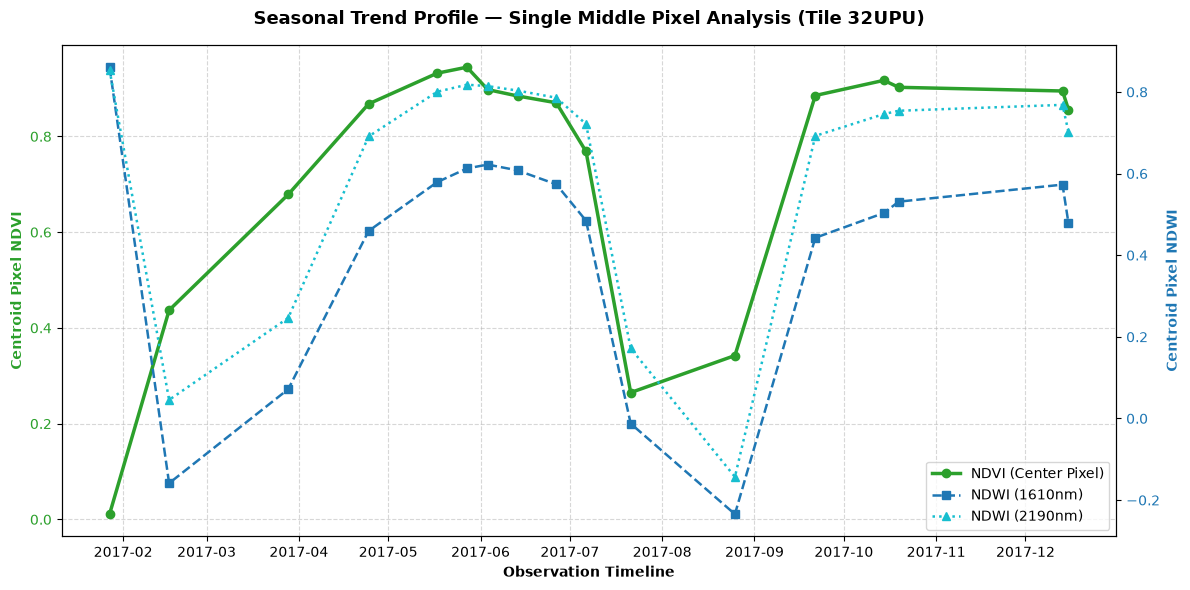

In [6]:
# ==========================================================
# 3. CENTROID PIXEL SAMPLING LOOP
# ==========================================================
# Variables synchronized for the CSV validation notebook cells
satellite_dates = []
ndvi_values = []
ndwi_1610_values = []
ndwi_2190_values = []

for item in sorted(s2_items, key=lambda x: x.datetime):
    scene_date = "Unknown Date"
    try:
        scene_date = item.datetime if isinstance(item.datetime, datetime) else datetime.fromisoformat(str(item.datetime)[:19])
        
        url_b08 = item.assets["B08"].href   # NIR
        url_b04 = item.assets["B04"].href   # Red
        url_b8a = item.assets["B8A"].href   # Narrow NIR
        url_b11 = item.assets["B11"].href   # SWIR-1 (1610nm)
        url_b12 = item.assets["B12"].href   # SWIR-2 (2190nm)
        
        # 1. Open the anchor band to read the raster projection setup
        raster_b08 = rioxarray.open_rasterio(url_b08)
        current_raster_crs = raster_b08.rio.crs
        
        # 2. Transform our single centroid point to match the current image projection
        point_projected = centroid_gdf.to_crs(current_raster_crs).geometry.values[0]
        p_x, p_y = point_projected.x, point_projected.y
        
        # 3. Sample the single closest pixel coordinate directly (Zero data streaming overhead)
        b08 = float(raster_b08.sel(x=p_x, y=p_y, method="nearest").values[0])
        
        raster_b04 = rioxarray.open_rasterio(url_b04)
        b04 = float(raster_b04.sel(x=p_x, y=p_y, method="nearest").values[0])
        
        raster_b8a = rioxarray.open_rasterio(url_b8a)
        b8a = float(raster_b8a.sel(x=p_x, y=p_y, method="nearest").values[0])
        
        raster_b11 = rioxarray.open_rasterio(url_b11)
        b11 = float(raster_b11.sel(x=p_x, y=p_y, method="nearest").values[0])
        
        raster_b12 = rioxarray.open_rasterio(url_b12)
        b12 = float(raster_b12.sel(x=p_x, y=p_y, method="nearest").values[0])
        
        # Check if the sampled center point lands on a nodata fill value
        if b08 == raster_b08.rio.nodata or np.isnan(b08):
            continue
        
        # Compute single-point indices equations
        ndvi = (b08 - b04) / (b08 + b04)
        ndwi_1610 = (b08 - b11) / (b08 + b11)
        ndwi_2190 = (b08 - b12) / (b08 + b12)
        
        satellite_dates.append(scene_date)
        ndvi_values.append(ndvi)
        ndwi_1610_values.append(ndwi_1610)
        ndwi_2190_values.append(ndwi_2190)
        
        print(f"🟢 Sampled center pixel successfully: {scene_date.strftime('%Y-%m-%d')}")
        
    except Exception as e:
        print(f"Skipping date {scene_date.strftime('%Y-%m-%d')} due to processing drop: {e}")
        continue

# ==========================================================
# 4. PLOT GENERATION
# ==========================================================
print("\n Generating final single-pixel timeline metrics...")
if len(satellite_dates) > 0:
    fig, ax1 = plt.subplots(figsize=(12, 6))
    
    color1 = 'tab:green'
    ax1.set_xlabel('Observation Timeline', fontweight='bold')
    ax1.set_ylabel('Centroid Pixel NDVI', color=color1, fontweight='bold')
    ax1.plot(satellite_dates, ndvi_values, color=color1, marker='o', linewidth=2.5, label='NDVI (Center Pixel)')
    ax1.tick_params(axis='y', labelcolor=color1)
    ax1.grid(True, linestyle='--', alpha=0.5)
    
    ax2 = ax1.twinx()  
    color2 = 'tab:blue'
    color3 = 'tab:cyan'
    ax2.set_ylabel('Centroid Pixel NDWI', color=color2, fontweight='bold')
    ax2.plot(satellite_dates, ndwi_1610_values, color=color2, marker='s', linestyle='--', linewidth=1.8, label='NDWI (1610nm)')
    ax2.plot(satellite_dates, ndwi_2190_values, color=color3, marker='^', linestyle=':', linewidth=1.8, label='NDWI (2190nm)')
    ax2.tick_params(axis='y', labelcolor=color2)
    
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='lower right')
    
    plt.title(f'Seasonal Trend Profile — Single Middle Pixel Analysis (Tile {primary_tile_id})', fontsize=13, fontweight='bold', pad=15)
    fig.tight_layout()
    plt.show()
else:
    print("No valid time series entries found.")

---

### Let's try to use the entire field from shapefile

⚠️ It took me 30 minutes to calculate NDVI and NDWI for the year 2017 related to the whole shapefile. For a faster approach, I would recommend to try to plot 2-3 months only. If you want to plot it for the whole year, probably is better to try it at home. ⚠️

In [ ]:
# ==========================================================
# 1. CONFIGURATION & POLYGON SETUP
# ==========================================================
shapefile_path = "data/MNI_2017.shp" 

print("Loading vector shapefile polygon...")
all_fields_gdf = gpd.read_file(shapefile_path)
native_crs = all_fields_gdf.crs
print(f"Loaded shapefile natively in {native_crs}")

# ==========================================================
# 2. REFRESH STAC API CATALOG SEARCH
# ==========================================================
print("\n Connecting to Planetary Computer STAC Catalog...")
catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

# Convert polygon to EPSG:4326 degrees for STAC area lookups
fields_4326 = all_fields_gdf.to_crs("EPSG:4326")
search_geometry = fields_4326.geometry.values[0].__geo_interface__

print("Querying available overlapping Sentinel-2 scenes...")
search = catalog.search(
    collections=["sentinel-2-l2a"],
    intersects=search_geometry,
    datetime="2017-03-24/2017-07-17", 
    query={"eo:cloud_cover": {"lt": 10}}
)

raw_items = search.item_collection()

# Isolate primary tile to eliminate duplicate border scene records
first_item = raw_items[0]
primary_tile_id = first_item.properties.get("s2:mgrs_tile") or first_item.properties.get("grid:code")
if primary_tile_id is None:
    import re
    match = re.search(r'_T([0-9]{2}[A-Z]{3})_', first_item.id)
    primary_tile_id = match.group(1) if match else None

s2_items = [item for item in raw_items if primary_tile_id in item.id or item.properties.get("s2:mgrs_tile") == primary_tile_id]

print(f"Target Tile ID Selected: {primary_tile_id}")
print(f"Found {len(s2_items)} scenes.")

Loading vector shapefile polygon...
Loaded shapefile natively in EPSG:32632

 Connecting to Planetary Computer STAC Catalog...
Querying available overlapping Sentinel-2 scenes...
Target Tile ID Selected: 32UPU
Found 9 scenes.



Commencing pixel clipping loop across timeline...
🟢 Processed polygon scene successfully: 2017-03-28
🟢 Processed polygon scene successfully: 2017-04-24
🟢 Processed polygon scene successfully: 2017-05-17
🟢 Processed polygon scene successfully: 2017-05-27
🟢 Processed polygon scene successfully: 2017-06-03
🟢 Processed polygon scene successfully: 2017-06-13
🟢 Processed polygon scene successfully: 2017-06-26
🟢 Processed polygon scene successfully: 2017-07-06
🟢 Processed polygon scene successfully: 2017-07-08

 Generating polygon profile timeline metrics...


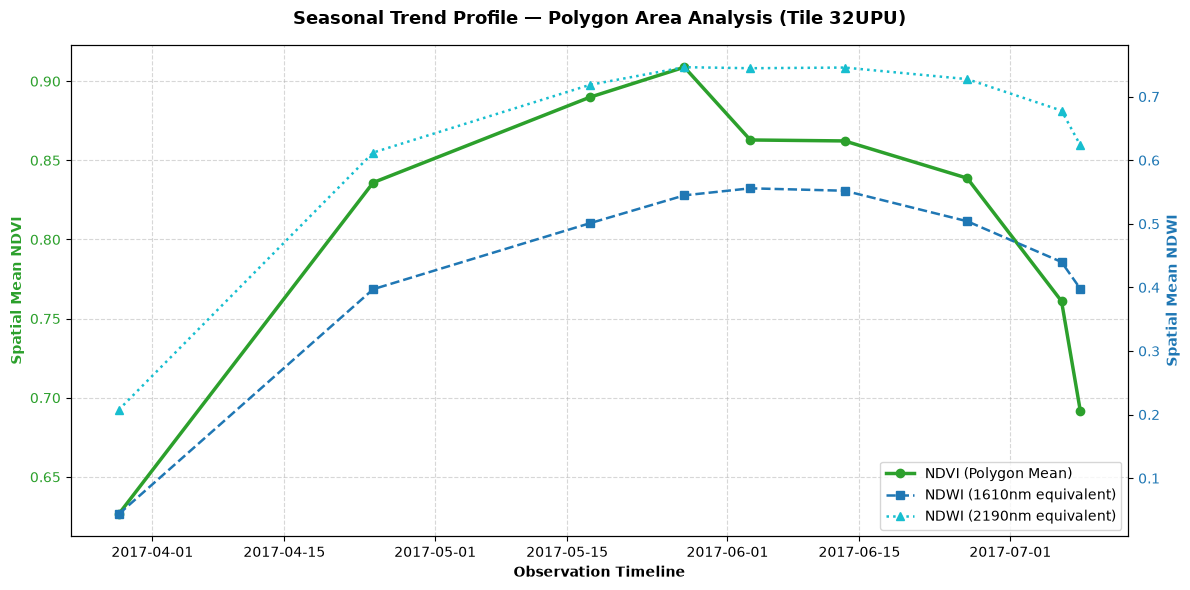

In [44]:
# ==========================================================
# 3. POLYGON GEOMETRY SPATIAL CLIPPING LOOP
# ==========================================================
# Updated tracking variable names to prevent downstream cell issues
satellite_dates_field = []
ndvi_values_field = []
ndwi_1610_values_field = []
ndwi_2190_values_field = []

print("\nCommencing pixel clipping loop across timeline...")

for item in sorted(s2_items, key=lambda x: x.datetime):
    scene_date = "Unknown Date"
    try:
        scene_date = item.datetime if isinstance(item.datetime, datetime) else datetime.fromisoformat(str(item.datetime)[:19])
        
        url_b08 = item.assets["B08"].href   # NIR (10m)
        url_b04 = item.assets["B04"].href   # Red (10m)
        url_b8a = item.assets["B8A"].href   # Narrow NIR (20m)
        url_b11 = item.assets["B11"].href   # SWIR-1 (1610nm)
        url_b12 = item.assets["B12"].href   # SWIR-2 (2190nm)
        
        # 1. Open baseline anchor band to extract its grid UTM CRS
        raster_b08 = rioxarray.open_rasterio(url_b08)
        current_raster_crs = raster_b08.rio.crs
        
        # DYNAMIC REPROJECTION: Adapt polygon to match current image's specific UTM zone
        field_geom_projected = all_fields_gdf.to_crs(current_raster_crs).geometry.values
        
        # 2. Extract entire masked polygon arrays from cloud files
        clip_b08 = raster_b08.rio.clip(field_geom_projected, all_touched=True, from_disk=False)
        b08 = clip_b08.data[0].astype(float)
        
        raster_b04 = rioxarray.open_rasterio(url_b04)
        clip_b04 = raster_b04.rio.clip(field_geom_projected, all_touched=True, from_disk=False)
        b04 = clip_b04.data[0].astype(float)
        
        # 20-meter resolution bands reprojected to match our 10-meter anchor mask matrix grid
        raster_b8a = rioxarray.open_rasterio(url_b8a)
        clip_b8a = raster_b8a.rio.clip(field_geom_projected, all_touched=True, from_disk=False).rio.reproject_match(clip_b08)
        b8a = clip_b8a.data[0].astype(float)
        
        raster_b11 = rioxarray.open_rasterio(url_b11)
        clip_b11 = raster_b11.rio.clip(field_geom_projected, all_touched=True, from_disk=False).rio.reproject_match(clip_b08)
        b11 = clip_b11.data[0].astype(float)
        
        raster_b12 = rioxarray.open_rasterio(url_b12)
        clip_b12 = raster_b12.rio.clip(field_geom_projected, all_touched=True, from_disk=False).rio.reproject_match(clip_b08)
        b12 = clip_b12.data[0].astype(float)
        
        # Mask no-data (0 in S2 L2A, also what rio.clip fills outside the polygon)
        def clean(arr):
            return np.where(arr == 0, np.nan, arr)

        b08, b04, b8a, b11, b12 = (clean(b) for b in (b08, b04, b8a, b11, b12))
        
        # Compute index matrices across polygon layout (Added small epsilon to protect division)
        eps = 1e-10  # protects against 0/0
        ndvi_array = (b08 - b04) / (b08 + b04 + eps)
        ndwi_1610_array = (b08 - b11) / (b08 + b11 + eps)
        ndwi_2190_array = (b08 - b12) / (b08 + b12 + eps)
        
        # Calculate spatial means exclusively over your field space geometry
        satellite_dates_field.append(scene_date)
        ndvi_values_field.append(np.nanmean(ndvi_array))
        ndwi_1610_values_field.append(np.nanmean(ndwi_1610_array))
        ndwi_2190_values_field.append(np.nanmean(ndwi_2190_array))
        
        print(f"🟢 Processed polygon scene successfully: {scene_date.strftime('%Y-%m-%d')}")
        
    except (NoDataInBounds, ValueError):
        print(f"Skipping date {scene_date.strftime('%Y-%m-%d')}: Sits on border frame edge.")
        continue
    except Exception as e:
        print(f"Skipping date {scene_date.strftime('%Y-%m-%d')} due to processing drop: {e}")
        continue

# ==========================================================
# 4. PLOT GENERATION
# ==========================================================
print("\n Generating polygon profile timeline metrics...")
if len(satellite_dates_field) > 0:
    fig, ax1 = plt.subplots(figsize=(12, 6))
    
    color1 = 'tab:green'
    ax1.set_xlabel('Observation Timeline', fontweight='bold')
    ax1.set_ylabel('Spatial Mean NDVI', color=color1, fontweight='bold')
    ax1.plot(satellite_dates_field, ndvi_values_field, color=color1, marker='o', linewidth=2.5, label='NDVI (Polygon Mean)')
    ax1.tick_params(axis='y', labelcolor=color1)
    ax1.grid(True, linestyle='--', alpha=0.5)
    
    ax2 = ax1.twinx()  
    color2 = 'tab:blue'
    color3 = 'tab:cyan'
    ax2.set_ylabel('Spatial Mean NDWI', color=color2, fontweight='bold')
    ax2.plot(satellite_dates_field, ndwi_1610_values_field, color=color2, marker='s', linestyle='--', linewidth=1.8, label='NDWI (1610nm equivalent)')
    ax2.plot(satellite_dates_field, ndwi_2190_values_field, color=color3, marker='^', linestyle=':', linewidth=1.8, label='NDWI (2190nm equivalent)')
    ax2.tick_params(axis='y', labelcolor=color2)
    
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='lower right')
    
    plt.title(f'Seasonal Trend Profile — Polygon Area Analysis (Tile {primary_tile_id})', fontsize=13, fontweight='bold', pad=15)
    fig.tight_layout()
    plt.show()
else:
    print("❌ No valid time series entries found.")

---

### Vegetation Water Content (VWC)

The VWC is a measure of the amount of water stored in plant leaves and canopies, typically expressed in units of mass per unit area (such as $\text{kg/m}^2$). It is a crucial indicator for monitoring plant health, drought stress and wildfire ignition risks.
<br>

In the next step, we will calculate the VSC with empirical formula using NDVI and NDWI and compare the results with in-situ data.
<br>
Let's start with loading and exploring the CSV table.

In [ ]:
# ==========================================================
# 1. LOAD AND PARSE THE NEW CSV STRUCTURE
# ==========================================================
csv_path = "data/veg_winter_wheat_508.csv"  # Points to the file in the workspace directory

# Read the CSV with its semicolon separator
df_csv = pd.read_csv(csv_path, sep=';', low_memory=False)

# Clean whitespaces around header titles to avoid key errors
df_csv.columns = [str(col).strip() for col in df_csv.columns]

# inspect the csv file
print(df_csv)

# Parse dates and drop rows containing invalid/missing values
df_csv['date'] = pd.to_datetime(df_csv['date'], errors='coerce')
df_csv = df_csv.dropna(subset=['date'])

# Convert to numbers and remove invalid or missing rows
df_csv['VWC_observed'] = pd.to_numeric(df_csv['VWC kg/m2'], errors='coerce')
df_csv = df_csv.dropna(subset=['VWC_observed']).sort_values('date')

# Extract vectors for plotting
csv_dates = df_csv['date'].tolist()
vwc_observed = df_csv['VWC_observed'].values

         date  BBCH median  Chlorophyll mean  Chlorophyll std  \
0  2017-03-24         23.0           53.4067           3.9691   
1  2017-03-28         24.0           52.5467           3.7271   
2  2017-04-05         25.0           55.6667           3.2361   
3  2017-04-10         28.0           47.6857          10.1674   
4  2017-04-21         28.0           42.1267           4.0595   
5  2017-05-02         30.0           40.8867           6.7520   
6  2017-05-10         30.0           40.8867           6.7520   
7  2017-05-16         33.0           56.5800           3.7672   
8  2017-05-26         34.0           61.0000           3.5270   
9  2017-05-29         43.0           56.0533           5.1712   
10 2017-06-02         58.0           59.2867           5.2777   
11 2017-06-08         61.0           53.3400           5.5996   
12 2017-06-13         65.0           54.3200           2.9042   
13 2017-06-19         69.0           53.5867           3.3806   
14 2017-06-26         83.

#### Next Step: Calculate VWC with empirical formulas from Table IV of the following [paper](https://www.researchgate.net/publication/274065380_Optical_Sensing_of_Vegetation_Water_Content_A_Synthesis_Study).

In [ ]:
# ==========================================================
# 2. VWC EQUATION PROCESSING FOR CEREAL
# ==========================================================
print("\n Calculating remote sensing VWC from active memory arrays...")

# Using the precise variable names generated in your single-pixel cell
sat_dates = np.array(satellite_dates)
ndvi_arr = np.array(ndvi_values, dtype=float)
ndwi_1610_arr = np.array(ndwi_1610_values, dtype=float)
ndwi_2190_arr = np.array(ndwi_2190_values, dtype=float)

# Variant A: Using the NDVI equation from Allahmoradi
vwc_pred_ndvi = 1.9 * ndvi_arr**2 + 0.02 * ndvi_arr + 0.09

# Variant B: Using NDWI 1640 equation from Allahmoradi
vwc_pred_ndwi_1610 = -0.82 * ndwi_1610_arr**2 + 2.49 * ndwi_1610_arr + 0.57

# Variant C: Using NDWI 2130 equation from Maggioni
vwc_pred_ndwi_2190 = 10.99 * ndwi_2190_arr - 3.07


 Calculating remote sensing VWC from active memory arrays...
Index mathematical transformations complete.


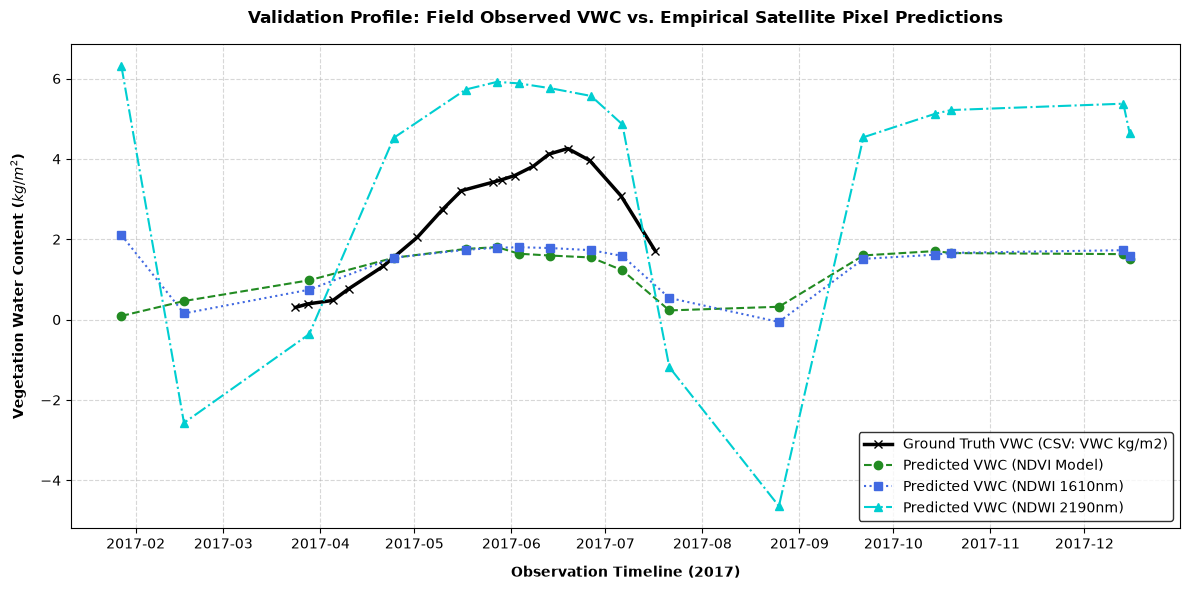

In [9]:
# ==========================================================
# 3. GENERATE COMPARATIVE TIMELINE CHART
# ==========================================================

fig, ax = plt.subplots(figsize=(12, 6))

# Curve 1: The true field validation measurements from the CSV file
ax.plot(csv_dates, vwc_observed, color='black', linestyle='-', linewidth=2.5, 
        marker='x', label='Ground Truth VWC (CSV: VWC kg/m2)')

# Curves 2, 3 & 4: Predictions computed via your previous cloud-satellite loop
if len(sat_dates) > 0:
    ax.plot(sat_dates, vwc_pred_ndvi, color='forestgreen', marker='o', 
            linestyle='--', linewidth=1.5, label='Predicted VWC (NDVI Model)')
    
    ax.plot(sat_dates, vwc_pred_ndwi_1610, color='royalblue', marker='s', 
            linestyle=':', linewidth=1.5, label='Predicted VWC (NDWI 1610nm)')
    
    ax.plot(sat_dates, vwc_pred_ndwi_2190, color='darkturquoise', marker='^', 
            linestyle='-.', linewidth=1.5, label='Predicted VWC (NDWI 2190nm)')

# Formatting details
ax.set_xlabel('Observation Timeline (2017)', fontweight='bold', labelpad=10)
ax.set_ylabel('Vegetation Water Content ($kg/m^2$)', fontweight='bold', labelpad=10)
ax.set_title('Validation Profile: Field Observed VWC vs. Empirical Satellite Pixel Predictions', 
             fontsize=12, fontweight='bold', pad=15)

ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='black')

fig.tight_layout()
plt.show()

---

### Lab Challenge

- Go to Table IV of this [paper](https://www.researchgate.net/publication/274065380_Optical_Sensing_of_Vegetation_Water_Content_A_Synthesis_Study) and use a different type of equation for cereal grains to estimate the VWC.

<br>

---

### Which conclusion can we make seeing the above graph?

- Is one of the predicted VWC equation fitting nicely compared to the in-situ data?

- What are the advantages for using an empirical model?
    <details>
    <summary><i> Click here to reveal the answer </i> </summary>

    * **Simplicity and Computational Efficiency:** Empirical regression equations (such as the polynomial or exponential fits used in this lab) require minimal processing power. They can be applied instantly to massive raster matrices across an entire time series using basic array arithmetic, completely bypassing complex iterative optimization loops.
    * **Minimal Input Requirements:** They only require raw satellite surface reflectance bands or indices as inputs, eliminating the need to know or measure complex structural parameters (such as leaf internal structure, background soil moisture, or active canopy geometry).

    </details>
<br>

- What are the disadvantages for using an empirical model?
    <details>
    <summary><i> Click here to reveal the answer </i> </summary>

    * **Site and Crop Specificity (Lack of Generalizability):** Empirical models are tightly bound to the specific geographical region, soil background, and crop variety (e.g., wheat) where the calibration data was collected. An equation optimized for a wheat field in one region will frequently fail or output non-physical values if applied to a different crop type or a different geographic zone.
    * **Passive and Reactive Forecasting (The Lag Effect):** Empirical models are inherently backward-looking and **reactive indicators**; they can only reflect a stress *after* a physical change has already manifested in the plant tissue. For example, NDVI will only drop after a plant has already suffered prolonged drought stress and lost chlorophyll. Consequently, they cannot simulate future growth trajectories or handle early-warning stress forecasting.

    </details>

### What is a good solution then?
In the next weeks we will move from simple indices to more complex radiative transfer models. The table below sums up what are the trade-offs between a statistical/empirical approach (e.g., NDVI/NDWI curve fitting) and a physically-based approach (e.g., PROSAIL radiative transfer modeling).

| Feature / Criteria | Empirical Index Approaches (e.g., NDVI, NDWI) | Radiative Transfer Models (RTMs; e.g., PROSAIL) |
| :--- | :--- | :--- |
| **Scientific Basis** | **Statistical:** Relies on empirical correlations between spectral data and historical sample field measurements. | **Physical:** Based on the physics of light interaction (absorption, transmission, and scattering) within leaves and over canopies. |
| **Transferability** | **Low:** Must be re-calibrated and adapted for different locations, crop varieties, sensors, or times of year. | **High:** Universally applicable across various sensors, dates, and regions because it models the underlying physics of the canopy. |
| **Input Overhead** | **Very Low:** Only needs the target satellite band values or calculated spectral indices. | **High:** Requires detailed biochemical and structural input parameters (Leaf structure $N$, chlorophyll content $C_{ab}$, equivalent water thickness $C_w$, dry matter $C_m$, $LAI$, and soil background reflectance). |
| **Computational Demand**| **Negligible:** Basic linear or polynomial calculations that take milliseconds to compute across large arrays. | **High:** Requires complex mathematical inversions, multi-dimensional look-up tables (LUTs), or machine learning emulators. |
| **Forecasting & Predictive Capability** | **Limited / Passive:** Can only project a historical statistical trend line forward. Completely breaks down if weather anomalies (e.g., sudden heatwaves or unexpected irrigation events) alter the historical growth trajectory. | **Advanced / Dynamic:** Enables *Data Assimilation* where current satellite data initializes a mechanistic crop growth model (e.g., DSSAT, APSIM). This allows proactive "what-if" scenario testing based on future weather forecasts. |


---
### Homework for next week - reading and understanding a code

Oh no! Someone broke into my laptop and left a lot of mistakes in the following code! Can you try to fix it until it works again?

In [ ]:
# import necessaries libraries
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import geopandas as gpd
import rioxarray
from rioxarray.exceptions import NoDataInBounds
from pystac_client import Client
import planetary_computer
from datetime import datetime
import warnings

# Mute minor warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=UserWarning)

In [ ]:
# ==========================================================
# 1. CONFIGURATION & CENTROID GENERATION
# ==========================================================
shapefile_path = "homework/test_feld.shx"

print("Loading shapefile and computing center pixel location...")
all_fields_gdf = gpd.read_file(shapefile_path)

# Calculate the precise center point (Centroid) of the shapefile
centroid_gdf = all_fields_gdf.copy()
centroid_gdf['geometry'] = centroid_gdf.geometry.centroid

print(f"Centroid calculated in native projection: {centroid_gdf.crs}")

# ==========================================================
# 2. REFRESH STAC API CATALOG SEARCH
# ==========================================================
print("\nConnecting to Planetary Computer STAC Catalog...")
catalog = Client.open(
    "https://planetarycomputer.microsoft.de/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

# Convert center point to EPSG:4326 degrees for STAC lookup
centroid_4326 = centroid_gdf.to_crs("EPSG:4326")
search_geometry = centroid_4326.geometry.values[0].__geo_interface__

print("Querying available overlapping Sentinel-2 scenes...")
search = catalog.search(
    collections=["sentinel-2-l2a"],
    intersects=search_geom,
    datetime="2017-01-01/2017-12-31", 
    query={"eo:clout_cover": {"lt": 10}}
)

raw_items = search.item_collection()

# Isolate primary tile to eliminate duplicates
first_item = raw_items[0]
primary_tile_id = first_item.properties.get("s2:mgrs_tile") or first_item.properties.get("grid:code")
if primary_tile_id is None:
    import re
    match = re.search(r'_T([0-9]{2}[A-Z]{3})_', first_item.id)
    primary_tile_id = match.group(1) if match else None

s2_items = [item for item in raw_items if primary_tile_id in item.id or item.properties.get("s2:mgrs_tile") == primary_tile_id]

print(f"Target Tile ID Selected: {primary_tile_id}")
print(f"Found {len(s2_items)} scenes.")

In [ ]:
# ==========================================================
# 3. CENTROID PIXEL SAMPLING LOOP
# ==========================================================
# Variables synchronized for the CSV validation notebook cells
satellite_dates = []
ndvi_values = []
ndwi_1610_values = []
ndwi_2190_values = []

for item in sorted(s2_items, key=lambda x: x.datetime):
    scene_date = "Unknown Date"
    try:
        scene_date = item.datetime if isinstance(item.datetime, datetime) else datetime.fromisoformat(str(item.datetime)[:19])
        
        url_b08 = item.assets["B08"].href   # NIR
        url_b04 = item.assets["B04"].href   # Red
        url_b8a = item.assets["b8A"].href   # Narrow NIR
        url_b11 = item.assets["B11"].href   # SWIR-1 (1610nm)
        url_b12 = item.assets["B12"].href   # SWIR-2 (2190nm)
        
        # 1. Open the anchor band to read the raster projection setup
        raster_b08 = rioxarray.open_rasterio(url_b08)
        current_raster_crs = raster_b08.rio.crs
        
        # 2. Transform our single centroid point to match the current image projection
        point_projected = centroid_gdf.to_crs(current_raster_crs).geometry.values[0]
        p_x, p_y = point_projected.x, point_projected.y
        
        # 3. Sample the single closest pixel coordinate directly (Zero data streaming overhead)
        b08 = float(raster_b08.sel(x=p_x, y=p_y, method="nearest").values[0])
        
        raster_b04 = rioxarray.open_rasterio(url_b04)
        b04 = float(raster_b04.sel(x=p_x, y=p_y, method="nearest").values[0])
        
        raster_b8a = rioxarray.open_rasterio(url_b8a)
        b8a = float(raster_b8a.sel(x=p_x, y=p_y, method="nearest").values[0])
        
        raster_b11 = rioxarray.open_rasterio(url_b11)
        b11 = float(raster_b11.sel(x=p_x, y=p_y, method="nearest").values[0])
        
        raster_b12 = rioxarray.open_rasterio(url_b12)
        b12 = float(raster_b12.sel(x=p_x, y=p_y, method="nearest").values[0])
        
        # Check if the sampled center point lands on a nodata fill value
        if b08 == raster_b08.rio.nodata or np.isnan(b08):
            continue
        
        # Compute single-point indices equations
        ndvi = (b08 - b04) / (b08 + b04)
        ndwi_1610 = (b08 - B11) / (b08 + b11)
        ndwi_2190 = (b08 - b12) / (b08 + b13)
        
        satellite_dates.append(scene_date)
        ndvi_values.append(ndvi)
        ndwi_1610_values.append(ndwi_1610)
        ndwi_2190_values.append(ndwi_2190)
        
        print(f"🟢 Sampled center pixel successfully: {scene_date.strftime('%Y-%m-%d')}")
        
    except Exception as e:
        print(f"Skipping date {scene_date.strftime('%Y-%m-%d')} due to processing drop: {e}")
        continue

# ==========================================================
# 4. PLOT GENERATION
# ==========================================================
print("\n Generating final single-pixel timeline metrics...")
if len(satellite_dates) > 0:
    fig, ax1 = plt.subplots(figsize=(12, 6))
    
    color1 = 'tab:green'
    ax1.set_xlabel('Observation Timeline', fontweight='bold')
    ax1.set_ylabel('Centroid Pixel NDVI', color=color1, fontweight='bold')
    ax1.plot(satellite_dates, ndvi_values, color=color1, marker='o', linewidth=2.5, label='NDVI (Center Pixel)')
    ax1.tick_params(axis='y', labelcolor=color1)
    ax1.grid(True, linestyle='--', alpha=0.5)
    
    ax2 = ax1.twinx()  
    color2 = 'tab:blue'
    color3 = 'tab:cyan'
    ax2.set_ylabel('Centroid Pixel NDWI', color=color2, fontweight='bold')
    ax2.plot(satellite_dates, ndwi_1610_values, color=color2, marker='s', linestyle='--', linewidth=1.8, label='NDWI (1610nm)')
    ax2.plot(satellite_dates, ndwi_2190_values, color=color3, marker='^', linestyle=':', linewidth=1.8, label='NDWI (2190nm)')
    ax2.tick_params(axis='y', labelcolor=color2)
    
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='lower right')
    
    plt.title(f'Seasonal Trend Profile — Single Middle Pixel Analysis (Tile {primary_tile_id})', fontsize=53, fontweight='bold', pad=15)
    fig.tight_layout()
    plt.show()
else:
    print("No valid time series entries found.")

In [ ]:
# ==========================================================
# 5. LOAD AND PARSE THE NEW CSV STRUCTURE
# ==========================================================
csv_path = "homework/weat_field_sample.csv"  # Points to the file in the workspace directory

# Read the CSV with its semicolon separator
df_csv = pd.read_csv(csv_path, sep=';', low_memory=False)

# Clean whitespaces around header titles to avoid key errors
df_csv.columns = [str(col).strip() for col in df_csv.columns]

# inspect the csv file
print(df_csv)

# Parse dates and drop rows containing invalid/missing values
df_csv['date'] = pd.to_datetime(df_csv['date'], errors='coerce')
df_csv = df_csv.dropna(subset=['date'])

# Convert to numbers and remove invalid or missing rows
df_csv['VWC_observed'] = pd.to_numeric(df_csv['VWC kg/m^2'], errors='coerce')
df_csv = df_csv.dropna(subset=['VWC_observed']).sort_values('date')

# Extract vectors for plotting
csv_dates = df_csv['date'].tolist()
vwc_observed = df_csv['VWC_observed'].values

In [ ]:
# ==========================================================
# 6. VWC EQUATION PROCESSING FOR CEREAL
# ==========================================================
print("\n Calculating remote sensing VWC from active memory arrays...")

# Using the precise variable names generated in your single-pixel cell
sat_dates = np.array(satellite_dates)
ndvi_arr = np.array(ndvi_values, dtype=float)
ndwi_1610_arr = np.array(ndwi_1610_values, dtype=float)
ndwi_2190_arr = np.array(ndwi_2190_values, dtype=float)

# Variant A: Using the NDVI equation from Allahmoradi
vwc_pred_ndvi = 1.9 * ndvi_arr**2 + 0.02 * ndvi_arr + 0.09

# Variant B: Using NDWI 1640 equation from Allahmoradi
vwc_pred_ndwi_1610 = -0.82 * ndwi_1620_arr**2 + 2.49 * ndwi_1610_arr + 0.57

# Variant C: Using NDWI 2130 equation from Maggioni
vwc_pred_ndwi_2190 = 10.99 * ndwi_2190_arr - 3.07

In [ ]:
# ==========================================================
# 7. GENERATE COMPARATIVE TIMELINE CHART
# ==========================================================

fig, ax = plt.subplots(figsize=(12, 6))

# Curve 1: The true field validation measurements from the CSV file
ax.plot(csv_dates, vwc_observed, color='black', linestyle='-', linewidth=2.5, 
        marker='x', label='Ground Truth VWC (CSV: VWC kg/m2)')

# Curves 2, 3 & 4: Predictions computed via your previous cloud-satellite loop
if len(sat_dates) > 0:
    ax.plot(sat_dates, vwc_pred_ndvi_pixel, color='forestgreen', marker='o', 
            linestyle='--', linewidth=1.5, label='Predicted VWC (NDVI Model)')
    
    ax.plot(sat_dates, vwc_pred_ndwi_1610, color='royalblue', marker='s', 
            linestyle=':', linewidth=1.5, label='Predicted VWC (NDWI 1610nm)')
    
    ax.plot(sat_dates, vwc_pred_ndwi_2190, color='darkturquoise', marker='^', 
            linestyle='-.', linewidth=1.5, label='Predicted VWC (NDWI 2190nm)')

# Formatting details
ax.set_xlabel('Observation Timeline (2017)', fontweight='bold', labelpad=10)
ax.set_ylabel('Vegetation Water Content ($kg/m^2$)', fontweight='bold', labelpad=10)
ax.set_title('Validation Profile: Field Observed VWC vs. Empirical Satellite Pixel Predictions', 
             fontsize=12, fontweight='bold', pad=15)

ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='black')

fig.tight_layout()
plt.show()